In [2]:
# 0. Kurulum
import os, sys, re, gzip, json, glob, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
warnings.filterwarnings('ignore', category=RuntimeWarning)

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/Donem_Projesi_Losemi'
else:
    BASE = os.environ.get('PROJE_BASE', './Donem_Projesi_Losemi')

GOLUB_DIR = os.path.join(BASE, '01_Ana_Veri_Seti_Golub')
GSE_DIR   = os.path.join(BASE, '03_Ikinci_Veri_Seti_GSE13159')
OUT       = os.path.join(BASE, '06_Ara_Rapor', 'ek_analiz_cikti')
os.makedirs(OUT, exist_ok=True)
for p in [GOLUB_DIR, GSE_DIR]:
    assert os.path.isdir(p), f'Klasör yok: {p}'

SEED = 42
PAL = {'ALL': '#1f77b4', 'AML': '#d9541e'}
sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
plt.rcParams.update({'savefig.dpi': 300, 'savefig.bbox': 'tight'})
R = {}                       # tüm sayılar buraya; sonda JSON'a yazılır

def kaydet(ad):
    yol = os.path.join(OUT, ad); plt.savefig(yol); print('Kaydedildi:', yol); plt.show(); plt.close('all')

def bh(p):
    """Benjamini–Hochberg (golub_eda_ek.py ile aynı)."""
    p = np.nan_to_num(np.asarray(p, float), nan=1.0); n = p.size; o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1); q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1); return out

def cohen_d(A, B, axis):
    """A, B: örnekler `axis` boyunca. Havuzlanmış s.s. ile Cohen d (A − B)."""
    nA, nB = A.shape[axis], B.shape[axis]
    sp = np.sqrt(((nA - 1) * np.nanvar(A, axis=axis, ddof=1) + (nB - 1) * np.nanvar(B, axis=axis, ddof=1)) / (nA + nB - 2))
    return (np.nanmean(A, axis=axis) - np.nanmean(B, axis=axis)) / np.where(sp == 0, np.nan, sp)

def semboller(s):
    """GEO 'Gene symbol' alanı çok genli problarda 'A///B' biçimindedir (BOŞLUKSUZ).
    v3 defterindeki hata: prob listeleri ' /// ' (boşluklu) ile bölünüyordu."""
    return [x.strip() for x in str(s).split('///') if x.strip()]

def read_annot(path):
    with gzip.open(path, 'rt', encoding='utf-8', errors='replace') as f:
        for i, line in enumerate(f):
            if line.startswith('ID\t'):
                break
    a = pd.read_csv(path, sep='\t', skiprows=i, dtype=str, compression='gzip')
    return a[~a['ID'].astype(str).str.startswith('!')].set_index('ID')
print('BASE:', BASE); print('OUT :', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE: /content/drive/MyDrive/Donem_Projesi_Losemi
OUT : /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti


In [3]:
train = pd.read_csv(os.path.join(GOLUB_DIR, 'data_set_ALL_AML_train.csv'))
test  = pd.read_csv(os.path.join(GOLUB_DIR, 'data_set_ALL_AML_independent.csv'))
lab   = pd.read_csv(os.path.join(GOLUB_DIR, 'actual.csv')).set_index('patient')['cancer']

def golub_matris(df):
    pats = [c for c in df.columns if re.fullmatch(r'\d+', str(c))]
    X = df[pats].apply(pd.to_numeric).T
    X.index = [int(p) for p in pats]; X.columns = df['Gene Accession Number'].values
    return X

Xtr, Xte = golub_matris(train), golub_matris(test)
Xall = pd.concat([Xtr, Xte]); yall = lab.reindex(Xall.index)
assert Xall.shape == (72, 7129) and yall.notna().all()
Xp = np.log2(Xall.clip(20, 16000)); Xp = Xp.loc[:, (Xp.max() - Xp.min()) > 0]   # ortamdan bağımsız sıfır varyans filtresi
Zg = StandardScaler().fit_transform(Xp)
Pg = PCA(n_components=20, random_state=SEED).fit(Zg).transform(Zg)
is_tr = np.isin(Xall.index, Xtr.index); mA = (yall == 'ALL').to_numpy()
print('Golub:', Xp.shape, '(örnek × prob, sıfır varyans sonrası)')

eski_json = os.path.join(BASE, '06_Ara_Rapor', 'golub_eda_sonuclar.json')
if os.path.exists(eski_json):
    eski = json.load(open(eski_json))
    for k, rec in enumerate(eski['pc_batch']):
        p_yeni = stats.ttest_ind(Pg[is_tr, k], Pg[~is_tr, k], equal_var=False).pvalue
        assert np.isclose(p_yeni, rec['p_welch'], rtol=1e-6), (k, p_yeni, rec['p_welch'])
    print('Kontrol: PC1–PC5 eğitim–test p değerleri golub_eda_sonuclar.json ile aynı ✓')

Golub: (72, 6832) (örnek × prob, sıfır varyans sonrası)
Kontrol: PC1–PC5 eğitim–test p değerleri golub_eda_sonuclar.json ile aynı ✓


grup,tümü,yalnız ALL,yalnız AML
PC,,,
1,4.2e-03,4.6e-03,1.7e-01
2,3.9e-01,7.3e-01,9.6e-01
3,4.9e-01,8.2e-01,3.6e-02
4,1.4e-04,2.1e-02,1.6e-03
5,2.3e-02,6.2e-04,3.9e-01


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti/golub_fig8_pc_kayma.png


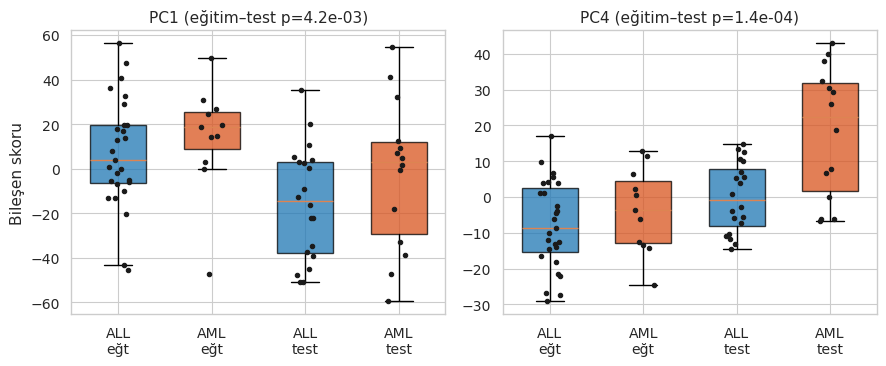

In [4]:
rows = []
for k in range(5):
    for ad, m in [('tümü', np.ones_like(mA)), ('yalnız ALL', mA), ('yalnız AML', ~mA)]:
        a, b = Pg[is_tr & m, k], Pg[~is_tr & m, k]
        rows.append({'PC': k + 1, 'grup': ad, 'n_egitim': len(a), 'n_test': len(b),
                     'p_welch': stats.ttest_ind(a, b, equal_var=False).pvalue,
                     'p_mwu': stats.mannwhitneyu(a, b).pvalue})
pc_sinif = pd.DataFrame(rows)
display(pc_sinif.pivot(index='PC', columns='grup', values='p_welch').map(lambda v: f'{v:.1e}'))
pc_sinif.to_csv(os.path.join(OUT, 'golub_pc_egitim_test_sinif_ici.csv'), index=False)
R['golub_pc_sinif_ici'] = pc_sinif.to_dict('records')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
gruplar = [('ALL', True, 'ALL\neğt'), ('AML', True, 'AML\neğt'), ('ALL', False, 'ALL\ntest'), ('AML', False, 'AML\ntest')]
for ax, k in zip(axes, [0, 3]):
    veri = [Pg[(yall == c).to_numpy() & (is_tr == t), k] for c, t, _ in gruplar]
    bp = ax.boxplot(veri, widths=.6, patch_artist=True, showfliers=False)
    for patch, (c, _, _) in zip(bp['boxes'], gruplar):
        patch.set_facecolor(PAL[c]); patch.set_alpha(.75)
    rng = np.random.default_rng(SEED)
    for i, v in enumerate(veri, 1):
        ax.scatter(i + rng.uniform(-.12, .12, len(v)), v, s=10, c='k', zorder=3)
    p_all = pc_sinif.query('PC == @k + 1 and grup == "tümü"').p_welch.item()
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([g[2] for g in gruplar])
    ax.set_title(f'PC{k + 1} (eğitim–test p={p_all:.1e})'); ax.set_ylabel('Bileşen skoru' if k == 0 else '')
plt.tight_layout(); kaydet('golub_fig8_pc_kayma.png')

In [5]:
a80  = read_annot(os.path.join(GSE_DIR, 'GPL80.annot.gz'))
a570 = read_annot(os.path.join(GSE_DIR, 'GPL570.annot.gz'))

def prob_gen_tablosu(annot, problar):
    s = annot['Gene symbol'].reindex(problar).dropna()
    return pd.DataFrame([(p, g) for p, v in s.items() for g in semboller(v)], columns=['prob', 'gen'])

# GSE13159: yalnızca tüm örneklerde sonlu değeri olan problar (v3 ile aynı ölçüt)
lab_gse = pd.read_csv(os.path.join(GSE_DIR, 'GSE13159_ALL_AML_labels.csv'))
pq = os.path.join(GSE_DIR, 'GSE13159_ALL_AML_expression.parquet'); pk = pq.replace('.parquet', '.pkl')
expr = pd.read_parquet(pq) if os.path.exists(pq) else pd.read_pickle(pk)
expr = expr[lab_gse.geo_accession]                     # sütun sırası = etiket sırası
y_gse = lab_gse.ALL_AML_group.to_numpy(); doku = lab_gse.sample_type.to_numpy()
sonlu = np.isfinite(expr.to_numpy()).all(axis=1)
print('GSE13159:', expr.shape, '| tüm örneklerde sonlu prob:', int(sonlu.sum()))

pg80  = prob_gen_tablosu(a80,  Xall.columns)            # Golub: 7.129 prob (filtre öncesi)
pg570 = prob_gen_tablosu(a570, expr.index[sonlu])
ortak = sorted(set(pg80.gen) & set(pg570.gen))
eski_map = pd.read_csv(os.path.join(GSE_DIR, 'Golub_GSE13159_ortak_gen_eslestirme.csv'))
bos_eski = int((eski_map.golub_problari_GPL80.isna() | eski_map.gse13159_problari_GPL570.isna()).sum())

var570 = expr.loc[sonlu].var(axis=1)
gmap = pd.DataFrame({'gen_sembolu': ortak})
gmap['golub_problari_GPL80']      = gmap.gen_sembolu.map(pg80.groupby('gen').prob.apply(';'.join))
gmap['gse13159_problari_GPL570']  = gmap.gen_sembolu.map(pg570.groupby('gen').prob.apply(';'.join))
gmap['gse13159_en_degisken_prob'] = gmap.gse13159_problari_GPL570.map(lambda s: var570.loc[s.split(';')].idxmax())
assert gmap.notna().all().all(), 'Düzeltilmiş tabloda boş hücre kalmamalı'
gmap.to_csv(os.path.join(GSE_DIR, 'Golub_GSE13159_ortak_gen_eslestirme_v2.csv'), index=False)

R['eslestirme'] = {'golub_sembol': int(pg80.gen.nunique()), 'gse_sembol': int(pg570.gen.nunique()),
                   'ortak_sembol': len(ortak), 'eski_tabloda_bos_satir': bos_eski,
                   'eski_tablo_satir': int(len(eski_map))}
print(R['eslestirme'])
print('Kaydedildi: Golub_GSE13159_ortak_gen_eslestirme_v2.csv', gmap.shape)

GSE13159: (54675, 1292) | tüm örneklerde sonlu prob: 54630
{'golub_sembol': 6071, 'gse_sembol': 22836, 'ortak_sembol': 6005, 'eski_tabloda_bos_satir': 798, 'eski_tablo_satir': 6005}
Kaydedildi: Golub_GSE13159_ortak_gen_eslestirme_v2.csv (6005, 4)


In [6]:
rng = np.random.default_rng(SEED)
Xg = expr.loc[sonlu].to_numpy(dtype=np.float32)
orn = rng.choice(Xg.ravel(), size=min(2_000_000, Xg.size), replace=False)
c_ham = float(stats.skew(orn))
c_log = float(stats.skew(np.log2(orn + np.quantile(orn[orn > 0], .01))))
R['gse_carpiklik'] = {'ham': round(c_ham, 3), 'log2_offset_sonrasi': round(c_log, 3)}
print(f'Ham çarpıklık: {c_ham:.3f} | log2(x + c) sonrası: {c_log:.3f}  → log dönüşümü çarpıklığı '
      f'{"azaltıyor" if abs(c_log) < abs(c_ham) else "azaltmıyor (sola çarpıtıyor)"}')

Ham çarpıklık: 0.697 | log2(x + c) sonrası: -0.905  → log dönüşümü çarpıklığı azaltmıyor (sola çarpıtıyor)


{
 "evren_gen": 5829,
 "golub_ayirt_edici": 359,
 "gse_ayirt_edici": 749,
 "ikisinde": 238,
 "beklenen": 46.1,
 "kat": 5.2,
 "p_hipergeometrik": 6.881381217683353e-136,
 "ayni_yon": 237,
 "pearson_d": 0.608,
 "spearman_d": 0.524
}


,golub_prob,golub_d,golub_q,gse_prob,gse_d,gse_q,yuksek,yon_uyumlu
MGST1,U46499_at,-3.14,1.0e-15,231736_x_at,-3.10,1.2e-291,AML,True
CFD,M84526_at,-3.56,6.7e-09,205382_s_at,-2.72,1.3e-296,AML,True
APLP2,L09209_s_at,-1.97,2.3e-11,208702_x_at,-2.67,5.2e-294,AML,True
CST3,M27891_at,-2.90,1.9e-14,201360_at,-2.39,2.3e-240,AML,True
CD33,M23197_at,-2.90,2.2e-11,206120_at,-2.24,1.1e-232,AML,True
MPO,M19507_at,-2.06,1.1e-09,203948_s_at,-1.50,2.6e-118,AML,True
TCF3,M31523_at,2.72,8.2e-14,209153_s_at,2.28,6.9e-204,ALL,True
DNTT,M11722_at,2.27,7.2e-10,210487_at,2.43,1.3e-210,ALL,True
CD79A,U05259_rna1_at,2.02,9.6e-08,205049_s_at,2.24,1.2e-243,ALL,True
CD79B,M89957_at,1.79,2.5e-10,205297_s_at,1.64,6.5e-159,ALL,True


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti/iki_set_cohen_d_karsilastirma.png


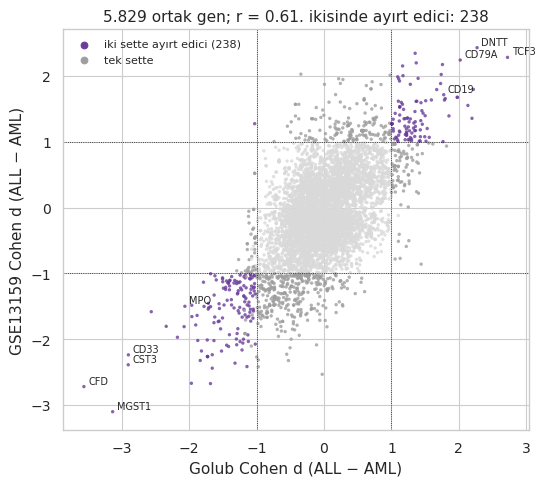

In [7]:
# Golub prob düzeyi (golub_eda_ek.py ile aynı test)
A, B = Xp[mA].to_numpy(), Xp[~mA].to_numpy()
_, p_g = stats.ttest_ind(A, B, axis=0, equal_var=False)
de_g = pd.DataFrame({'d': cohen_d(A, B, 0), 'p': p_g, 'q': bh(p_g)}, index=Xp.columns)

# GSE13159 prob düzeyi: v3'ün ürettiği tablo varsa onu kullan, yoksa hesapla
de_csv = os.path.join(GSE_DIR, 'GSE13159_ALL_vs_AML_ayirt_edici_genler.csv')
if os.path.exists(de_csv):
    t = pd.read_csv(de_csv, index_col='prob_id')
    de_s = pd.DataFrame({'d': t.cohen_d, 'p': t.p_welch, 'q': t.q_welch_BH})
else:
    Xs = expr.to_numpy(np.float32); As, Bs = Xs[:, y_gse == 'ALL'], Xs[:, y_gse == 'AML']
    _, p_s = stats.ttest_ind(As, Bs, axis=1, equal_var=False, nan_policy='omit')
    de_s = pd.DataFrame({'d': cohen_d(As, Bs, 1), 'p': p_s, 'q': bh(p_s)}, index=expr.index)
de_s = de_s.loc[de_s.index.intersection(expr.index[sonlu])].dropna()

def gen_duzeyi(de, pg):
    m = pg.merge(de, left_on='prob', right_index=True).dropna(subset=['d'])
    m = m.loc[m.groupby('gen').d.apply(lambda s: s.abs().idxmax())]
    return m.set_index('gen')[['prob', 'd', 'p', 'q']]

Gg, Gs = gen_duzeyi(de_g, pg80), gen_duzeyi(de_s, pg570)
evren = sorted(set(Gg.index) & set(Gs.index))
Gg, Gs = Gg.loc[evren], Gs.loc[evren]
sig_g = (Gg.q < .01) & (Gg.d.abs() > 1); sig_s = (Gs.q < .01) & (Gs.d.abs() > 1)
ikisi = sig_g & sig_s
N, K, n_, k_ = len(evren), int(sig_g.sum()), int(sig_s.sum()), int(ikisi.sum())
beklenen = K * n_ / N
p_hyper = stats.hypergeom.sf(k_ - 1, N, K, n_)
ayni_yon = int((np.sign(Gg.d[ikisi]) == np.sign(Gs.d[ikisi])).sum())
r_d = stats.pearsonr(Gg.d, Gs.d)[0]; rho_d = stats.spearmanr(Gg.d, Gs.d)[0]
R['ortak_ayirt_edici'] = {'evren_gen': N, 'golub_ayirt_edici': K, 'gse_ayirt_edici': n_, 'ikisinde': k_,
                          'beklenen': round(beklenen, 1), 'kat': round(k_ / beklenen, 1),
                          'p_hipergeometrik': float(p_hyper), 'ayni_yon': ayni_yon,
                          'pearson_d': round(float(r_d), 3), 'spearman_d': round(float(rho_d), 3)}
print(json.dumps(R['ortak_ayirt_edici'], indent=1))

# Tablo III: rapordaki genler, her iki sütun aynı kuralla
tablo3_genler = ['MGST1', 'CFD', 'APLP2', 'CST3', 'CD33', 'MPO', 'TCF3', 'DNTT', 'CD79A', 'CD79B', 'CD19', 'CCND3', 'LEF1']
G_all_g, G_all_s = gen_duzeyi(de_g, pg80), gen_duzeyi(de_s, pg570)
t3 = pd.DataFrame(index=tablo3_genler)
t3['golub_prob'] = G_all_g.prob.reindex(t3.index); t3['golub_d'] = G_all_g.d.reindex(t3.index); t3['golub_q'] = G_all_g.q.reindex(t3.index)
t3['gse_prob'] = G_all_s.prob.reindex(t3.index);  t3['gse_d'] = G_all_s.d.reindex(t3.index);  t3['gse_q'] = G_all_s.q.reindex(t3.index)
d_ref = t3.gse_d.fillna(t3.golub_d)
t3['yuksek'] = np.where(d_ref.isna(), '—', np.where(d_ref > 0, 'ALL', 'AML'))
t3['yon_uyumlu'] = np.sign(t3.golub_d) == np.sign(t3.gse_d)
t3.to_csv(os.path.join(OUT, 'tablo3_iki_set_ayirt_edici_genler.csv'))
display(t3.style.format({'golub_d': '{:.2f}', 'gse_d': '{:.2f}', 'golub_q': '{:.1e}', 'gse_q': '{:.1e}'}, na_rep='—'))
pd.DataFrame({'golub_prob': Gg.prob, 'golub_d': Gg.d, 'golub_q': Gg.q, 'gse_prob': Gs.prob, 'gse_d': Gs.d,
              'gse_q': Gs.q, 'golub_ayirt': sig_g, 'gse_ayirt': sig_s}).to_csv(os.path.join(OUT, 'gen_duzeyi_iki_set.csv'))

# Şekil: Golub d – GSE13159 d
fig, ax = plt.subplots(figsize=(5.6, 5))
renk = np.where(ikisi, '#6a3d9a', np.where(sig_g | sig_s, '#9e9e9e', '#d9d9d9'))
ax.scatter(Gg.d, Gs.d, c=renk, s=6, alpha=.8, linewidths=0)
for g in ['MGST1', 'CST3', 'CD33', 'MPO', 'CFD', 'TCF3', 'DNTT', 'CD79A', 'CD19', 'LEF1']:
    if g in Gg.index:
        ax.annotate(g, (Gg.d[g], Gs.d[g]), fontsize=7, xytext=(3, 2), textcoords='offset points')
for v in (-1, 1):
    ax.axvline(v, ls=':', c='k', lw=.6); ax.axhline(v, ls=':', c='k', lw=.6)
ax.set_xlabel("Golub Cohen d (ALL − AML)"); ax.set_ylabel("GSE13159 Cohen d (ALL − AML)")
ax.set_title(f'{N:,} ortak gen; r = {r_d:.2f}, ikisinde ayırt edici: {k_}'.replace(',', '.'))
ax.scatter([], [], c='#6a3d9a', label=f'iki sette ayırt edici ({k_})'); ax.scatter([], [], c='#9e9e9e', label='tek sette'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); kaydet('iki_set_cohen_d_karsilastirma.png')

ARI (k=2): 0.84


küme,1,2
gerçek,,
ALL,50,700
AML,538,4


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti/gse13159_top50_ayirt_edici_isi_haritasi.png


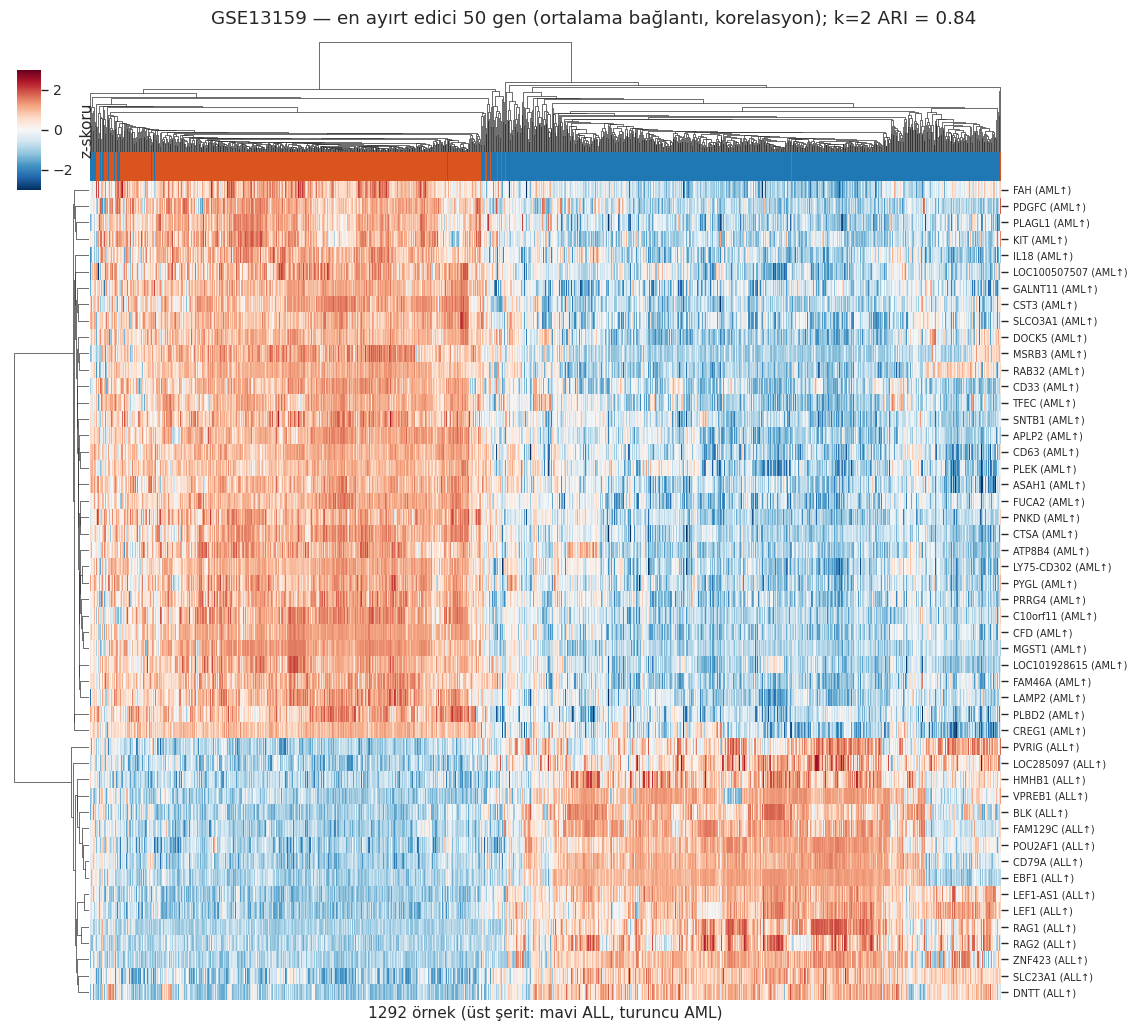

Top-50 içinde cinsiyet geni: yok


In [8]:
sym_tek = pg570.groupby('prob').gen.first()
de_s_sirali = de_s.sort_values('p').assign(gen=lambda d: sym_tek.reindex(d.index).values).dropna(subset=['gen'])
top50 = de_s_sirali.drop_duplicates('gen').head(50)
Z_gse = expr.loc[top50.index].to_numpy(np.float32)
Z_gse = ((Z_gse - Z_gse.mean(1, keepdims=True)) / Z_gse.std(1, keepdims=True)).T     # örnek × gen
L_s = linkage(Z_gse, method='average', metric='correlation')
cl2 = fcluster(L_s, 2, criterion='maxclust')
R['gse_top50_ari_k2'] = round(float(adjusted_rand_score(y_gse, cl2)), 3)
R['gse_top50_capraz'] = pd.crosstab(y_gse, cl2).to_dict()
print('ARI (k=2):', R['gse_top50_ari_k2']); display(pd.crosstab(pd.Series(y_gse, name='gerçek'), pd.Series(cl2, name='küme')))
H = pd.DataFrame(np.clip(Z_gse, -3, 3).T, index=[f'{g} ({"ALL" if d > 0 else "AML"}↑)' for g, d in zip(top50.gen, top50.d)])
g = sns.clustermap(H, col_linkage=L_s, method='average', metric='correlation', cmap='RdBu_r', vmin=-3, vmax=3,
                   col_colors=[PAL[c] for c in y_gse], xticklabels=False, yticklabels=True, figsize=(12, 10),
                   cbar_kws={'label': 'z-skoru'}, dendrogram_ratio=(.08, .12), cbar_pos=(.02, .83, .02, .12))
g.ax_heatmap.tick_params(axis='y', labelsize=7); g.ax_heatmap.set_xlabel(f'{len(y_gse)} örnek (üst şerit: mavi ALL, turuncu AML)')
g.fig.suptitle(f'GSE13159 — en ayırt edici 50 gen (ortalama bağlantı, korelasyon); k=2 ARI = {R["gse_top50_ari_k2"]:.2f}', y=1.01)
yol = os.path.join(OUT, 'gse13159_top50_ayirt_edici_isi_haritasi.png'); g.savefig(yol); print('Kaydedildi:', yol); plt.show(); plt.close('all')
cinsiyet = {'XIST', 'DDX3Y', 'EIF1AY', 'KDM5D', 'RPS4Y1', 'UTY', 'USP9Y', 'NLGN4Y', 'ZFY', 'TXLNGY'}
R['gse_top50_cinsiyet_geni'] = sorted(set(top50.gen) & cinsiyet)
print('Top-50 içinde cinsiyet geni:', R['gse_top50_cinsiyet_geni'] or 'yok')

sinif,ALL,AML
PC,,
1,2.4e-03,8.1e-01
2,5.5e-02,4.9e-01
3,2.8e-01,1.2e-02
4,1.6e-03,2.3e-01
5,5.3e-01,3.7e-02


{
 "ALL": {
  "q05": 5409,
  "q05_d1": 29,
  "q05_yuzde": 9.9
 },
 "AML": {
  "q05": 577,
  "q05_d1": 19,
  "q05_yuzde": 1.06
 }
} | ALL–AML (q<0,05, |d|>1): 2973
Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti/gse13159_doku_etkisi.png


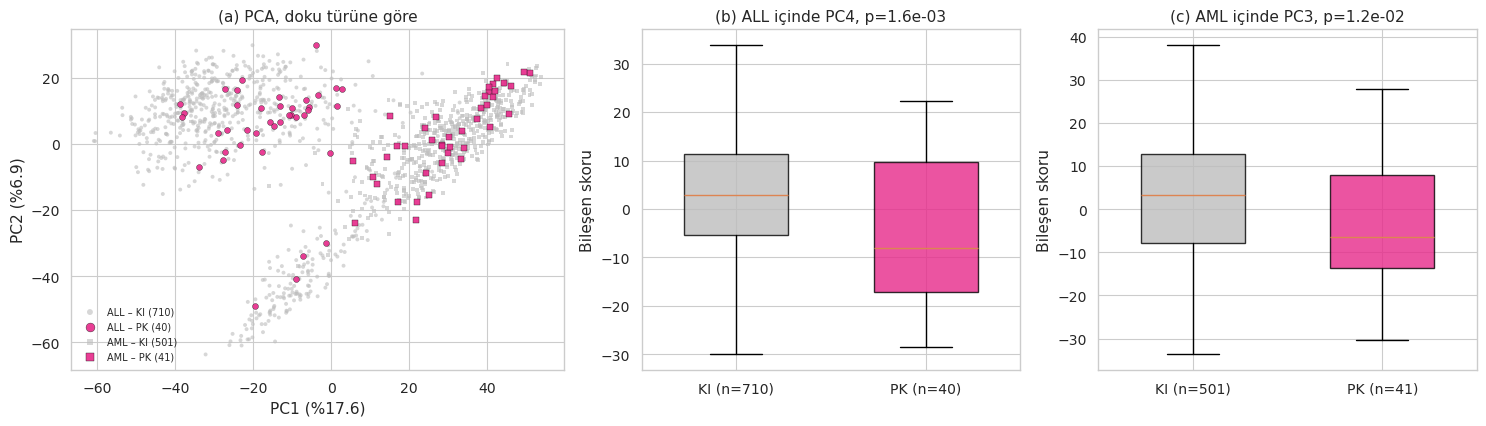

In [9]:
var_s = expr.loc[sonlu].var(axis=1)
top5k = var_s.sort_values(ascending=False).index[:5000]
Zt = expr.loc[top5k].to_numpy(np.float32).T
Zt = (Zt - Zt.mean(0)) / Zt.std(0)
pca_s = PCA(n_components=10, random_state=SEED).fit(Zt); Ps = pca_s.transform(Zt)
rows = []
for sinif in ['ALL', 'AML']:
    m = y_gse == sinif; ki, pk_ = m & (doku == 'bone marrow'), m & (doku == 'peripheral blood')
    for k in range(5):
        rows.append({'sinif': sinif, 'PC': k + 1, 'n_KI': int(ki.sum()), 'n_PK': int(pk_.sum()),
                     'p_welch': stats.ttest_ind(Ps[ki, k], Ps[pk_, k], equal_var=False).pvalue})
doku_pc = pd.DataFrame(rows)
display(doku_pc.pivot(index='PC', columns='sinif', values='p_welch').map(lambda v: f'{v:.1e}'))
Xs_ok = expr.loc[sonlu].to_numpy(np.float32)
doku_prob = {}
for sinif in ['ALL', 'AML']:
    m = y_gse == sinif
    a, b = Xs_ok[:, m & (doku == 'bone marrow')], Xs_ok[:, m & (doku == 'peripheral blood')]
    _, p = stats.ttest_ind(a, b, axis=1, equal_var=False); q = bh(p); d = cohen_d(a, b, 1)
    doku_prob[sinif] = {'q05': int((q < .05).sum()), 'q05_d1': int(((q < .05) & (np.abs(d) > 1)).sum()),
                        'q05_yuzde': round(100 * float((q < .05).mean()), 2)}
sinif_q05_d1 = int(((de_s.q < .05) & (de_s.d.abs() > 1)).sum())
R['gse_doku'] = {'pc_testleri': doku_pc.to_dict('records'), 'prob_duzeyi': doku_prob,
                 'karsilastirma_ALL_AML_q05_d1': sinif_q05_d1,
                 'pc_aciklanan_varyans': [round(100 * float(v), 2) for v in pca_s.explained_variance_ratio_[:5]]}
print(json.dumps(R['gse_doku']['prob_duzeyi'], indent=1), '| ALL–AML (q<0,05, |d|>1):', sinif_q05_d1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1.3, 1, 1]})
for sinif, mk in [('ALL', 'o'), ('AML', 's')]:
    for dk, renk, ad in [('bone marrow', '#bdbdbd', 'KI'), ('peripheral blood', '#e7298a', 'PK')]:
        m = (y_gse == sinif) & (doku == dk)
        axes[0].scatter(Ps[m, 0], Ps[m, 1], s=8 if dk == 'bone marrow' else 18, marker=mk, c=renk, alpha=.6 if dk == 'bone marrow' else .9,
                        edgecolor='none' if dk == 'bone marrow' else 'k', linewidth=.3, label=f'{sinif} – {ad} ({m.sum()})')
axes[0].set_xlabel(f'PC1 (%{100 * pca_s.explained_variance_ratio_[0]:.1f})'); axes[0].set_ylabel(f'PC2 (%{100 * pca_s.explained_variance_ratio_[1]:.1f})')
axes[0].set_title('(a) PCA, doku türüne göre'); axes[0].legend(frameon=False, fontsize=7, markerscale=1.5)
for ax, sinif, k in [(axes[1], 'ALL', 0), (axes[2], 'AML', 0)]:
    # her sınıfta KI–PK farkının en belirgin olduğu PC çizilir
    sub = doku_pc[doku_pc.sinif == sinif]; k = int(sub.loc[sub.p_welch.idxmin(), 'PC']) - 1
    m = y_gse == sinif
    veri = [Ps[m & (doku == 'bone marrow'), k], Ps[m & (doku == 'peripheral blood'), k]]
    bp = ax.boxplot(veri, widths=.55, patch_artist=True, showfliers=False)
    for patch, c in zip(bp['boxes'], ['#bdbdbd', '#e7298a']): patch.set_facecolor(c); patch.set_alpha(.8)
    ax.set_xticks([1, 2]); ax.set_xticklabels([f'KI (n={len(veri[0])})', f'PK (n={len(veri[1])})'])
    ax.set_title(f'({"b" if sinif == "ALL" else "c"}) {sinif} içinde PC{k + 1}, p={sub.p_welch.min():.1e}')
    ax.set_ylabel('Bileşen skoru')
plt.tight_layout(); kaydet('gse13159_doku_etkisi.png')

{
 "ortak_gen_temsil": 5829,
 "ortak_pca_gen": 5829,
 "spearman_ortalama_ifade": 0.401,
 "ortak_pca_varyans": [
  8.85,
  7.65,
  3.55
 ],
 "pc1_ALL_AML_cohen_d": {
  "Golub": -3.67,
  "GSE13159": -2.87
 }
}
Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti/iki_set_ortak_gen_karsilastirma.png


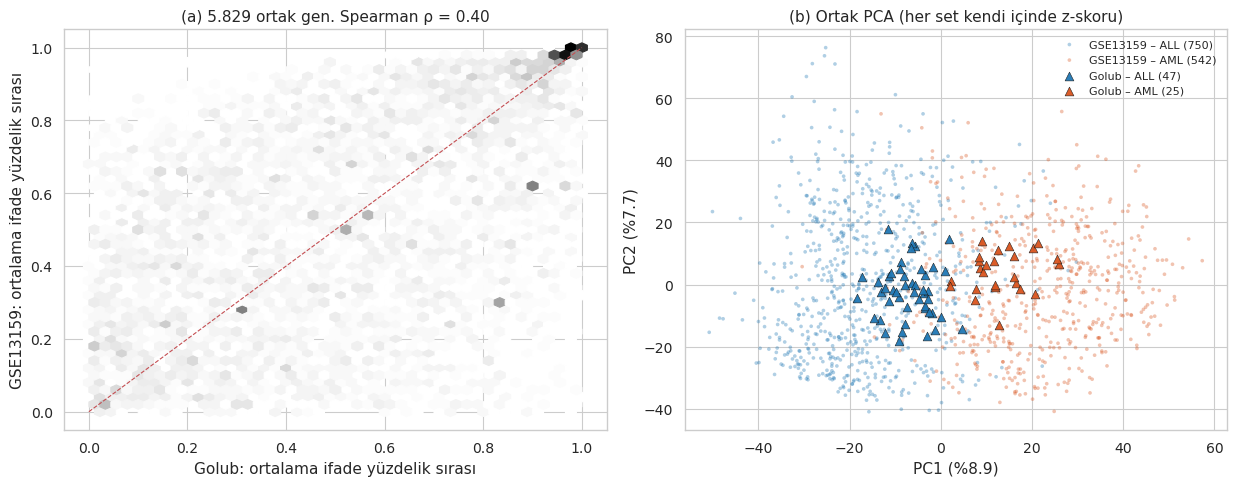

In [10]:
temsil_g = pg80[pg80.prob.isin(Xp.columns)].assign(v=lambda d: Xp.var().reindex(d.prob).values)
temsil_g = temsil_g.loc[temsil_g.groupby('gen').v.idxmax()].set_index('gen').prob
temsil_s = pg570.assign(v=lambda d: var570.reindex(d.prob).values)
temsil_s = temsil_s.loc[temsil_s.groupby('gen').v.idxmax()].set_index('gen').prob
ort_gen = sorted(set(temsil_g.index) & set(temsil_s.index))
Mg = Xp[temsil_g[ort_gen].values].to_numpy()                       # 72 × G (log2, kırpılmış)
Ms = expr.loc[temsil_s[ort_gen].values].to_numpy(np.float32).T     # 1292 × G (0–1)
rank_g = pd.Series(Mg.mean(0)).rank(pct=True).to_numpy(); rank_s = pd.Series(Ms.mean(0)).rank(pct=True).to_numpy()
rho_ort = stats.spearmanr(rank_g, rank_s)[0]
zg = (Mg - Mg.mean(0)) / Mg.std(0); zs = (Ms - Ms.mean(0)) / Ms.std(0)
ok = np.isfinite(zg).all(0) & np.isfinite(zs).all(0)
Zj = np.vstack([zg[:, ok], zs[:, ok]])
set_ad = np.array(['Golub'] * len(Mg) + ['GSE13159'] * len(Ms)); y_j = np.concatenate([yall.to_numpy(), y_gse])
pca_j = PCA(n_components=5, random_state=SEED).fit(Zj); Pj = pca_j.transform(Zj)
p_pc1_sinif = {s: float(stats.ttest_ind(Pj[(set_ad == s) & (y_j == 'ALL'), 0], Pj[(set_ad == s) & (y_j == 'AML'), 0], equal_var=False).pvalue) for s in ['Golub', 'GSE13159']}
d_pc1 = {s: float(cohen_d(Pj[(set_ad == s) & (y_j == 'ALL'), 0], Pj[(set_ad == s) & (y_j == 'AML'), 0], 0)) for s in ['Golub', 'GSE13159']}
R['iki_set_karsilastirma'] = {'ortak_gen_temsil': len(ort_gen), 'ortak_pca_gen': int(ok.sum()),
                              'spearman_ortalama_ifade': round(float(rho_ort), 3),
                              'ortak_pca_varyans': [round(100 * float(v), 2) for v in pca_j.explained_variance_ratio_[:3]],
                              'pc1_ALL_AML_cohen_d': {k: round(v, 2) for k, v in d_pc1.items()}}
print(json.dumps(R['iki_set_karsilastirma'], indent=1))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
axes[0].hexbin(rank_g, rank_s, gridsize=45, cmap='Greys', mincnt=1)
axes[0].plot([0, 1], [0, 1], 'r--', lw=.8)
axes[0].set_xlabel('Golub: ortalama ifade yüzdelik sırası'); axes[0].set_ylabel('GSE13159: ortalama ifade yüzdelik sırası')
axes[0].set_title(f'(a) {len(ort_gen):,} ortak gen, Spearman ρ = {rho_ort:.2f}'.replace(',', '.'))
for s, mk, sz, a_ in [('GSE13159', 'o', 7, .35), ('Golub', '^', 40, .95)]:
    for c in ['ALL', 'AML']:
        m = (set_ad == s) & (y_j == c)
        axes[1].scatter(Pj[m, 0], Pj[m, 1], marker=mk, s=sz, alpha=a_, c=PAL[c],
                        edgecolor='k' if s == 'Golub' else 'none', linewidth=.4, label=f'{s} – {c} ({m.sum()})')
axes[1].set_xlabel(f'PC1 (%{100 * pca_j.explained_variance_ratio_[0]:.1f})'); axes[1].set_ylabel(f'PC2 (%{100 * pca_j.explained_variance_ratio_[1]:.1f})')
axes[1].set_title('(b) Ortak PCA (her set kendi içinde z-skoru)'); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); kaydet('iki_set_ortak_gen_karsilastirma.png')

## 9. Sonuçların kaydı ve rapora girecek sayılar

In [12]:
yol = os.path.join(OUT, 'ek_analiz_sonuclar.json')
json.dump(R, open(yol, 'w'), indent=1, ensure_ascii=False, default=str)
print('Kaydedildi:', yol)
e, o = R['eslestirme'], R['ortak_ayirt_edici']
print(f"""


- Değerlendirilebilir ortak gen: {o['evren_gen']} | Golub'da ayırt edici: {o['golub_ayirt_edici']} | GSE13159'da: {o['gse_ayirt_edici']}
- İkisinde birden: {o['ikisinde']} (beklenen {o['beklenen']}, {o['kat']} kat, hipergeometrik p = {o['p_hipergeometrik']:.1e}); aynı yön: {o['ayni_yon']}/{o['ikisinde']}
- Golub d ile GSE13159 d arasında Pearson r = {o['pearson_d']}
- GSE13159 en ayırt edici 50 gen, k=2 ARI = {R['gse_top50_ari_k2']}
- Doku (KI–PK) etkisi, prob düzeyinde q<0,05: ALL {R['gse_doku']['prob_duzeyi']['ALL']['q05']}, AML {R['gse_doku']['prob_duzeyi']['AML']['q05']}
- Ortalama ifade sırası Spearman ρ = {R['iki_set_karsilastirma']['spearman_ortalama_ifade']}
- GSE13159 çarpıklık: ham {R['gse_carpiklik']['ham']}, log sonrası {R['gse_carpiklik']['log2_offset_sonrasi']}
""")

Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/06_Ara_Rapor/ek_analiz_cikti/ek_analiz_sonuclar.json



- Değerlendirilebilir ortak gen: 5829 | Golub'da ayırt edici: 359 | GSE13159'da: 749
- İkisinde birden: 238 (beklenen 46.1, 5.2 kat, hipergeometrik p = 6.9e-136); aynı yön: 237/238
- Golub d ile GSE13159 d arasında Pearson r = 0.608
- GSE13159 en ayırt edici 50 gen, k=2 ARI = 0.84
- Doku (KI–PK) etkisi, prob düzeyinde q<0,05: ALL 5409, AML 577
- Ortalama ifade sırası Spearman ρ = 0.401
- GSE13159 çarpıklık: ham 0.697, log sonrası -0.905

